# 02. Baselines and statistical models (naive rules, Prophet, SARIMAX)

Before any machine learning, how well do simple rules and classic per-store time-series models do?
This notebook defines the evaluation (three rolling forecast windows, 42 days each), scores the
naive baselines on every store, and then fits **Prophet** and **SARIMAX** one store at a time.

Per-store models cost one fit per store per window, so they run here on a handful of stores; the
full pipeline scores Prophet on a 100-store sample.

In [1]:
import warnings

warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rossmann_forecast.config import DEFAULT_ORIGINS, HORIZON, MIN_LAG
from rossmann_forecast.data import load_panel
from rossmann_forecast.metrics import all_metrics, wape
from rossmann_forecast.plotting import COLORS, NAMES, apply_style, find_root
from rossmann_forecast.splits import rolling_origin_folds

apply_style()
ROOT = find_root()
panel = load_panel(ROOT / "data")
folds = rolling_origin_folds(DEFAULT_ORIGINS, HORIZON, panel.dates[-1])
final_fold = folds[-1]
print(f"{len(panel.stores):,} stores, {panel.dates[0].date()} to {panel.dates[-1].date()}")

1,115 stores, 2013-01-01 to 2015-07-31


## 1. The evaluation: rolling forecast windows

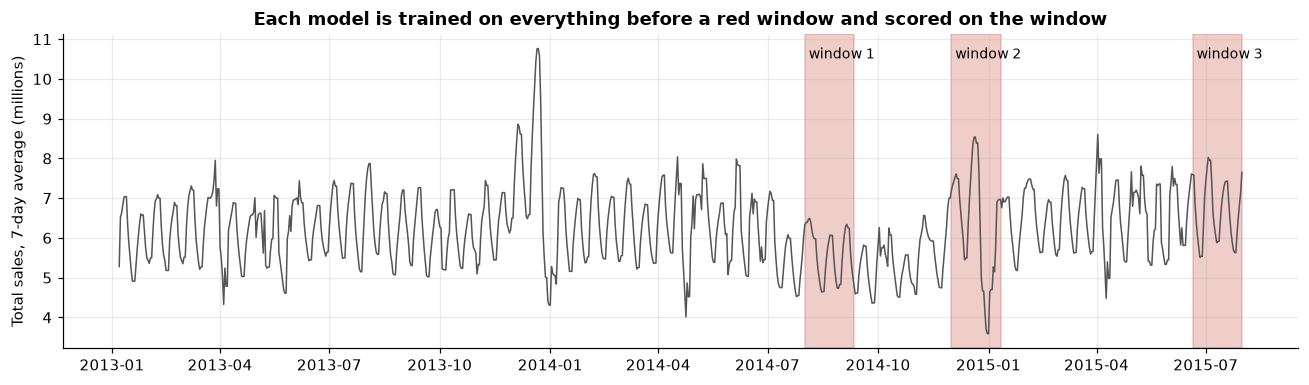

,forecast origin,last day forecast,model may use data up to
window 1,2014-08-01,2014-09-11,2014-07-31
window 2,2014-12-01,2015-01-11,2014-11-30
window 3,2015-06-20,2015-07-31,2015-06-19


In [2]:
table = pd.DataFrame(
    {
        "forecast origin": [str(f.test_start.date()) for f in folds],
        "last day forecast": [str(f.test_end.date()) for f in folds],
        "model may use data up to": [str(f.train_end.date()) for f in folds],
    },
    index=[f"window {f.index}" for f in folds],
)
total = panel.sales.sum(axis=1) / 1e6
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(total.index, total.rolling(7).mean(), color="#555", lw=1)
for f in folds:
    ax.axvspan(f.test_start, f.test_end, color=COLORS["lightgbm"], alpha=0.25)
    ax.text(f.test_start, ax.get_ylim()[1] * 0.97, f" window {f.index}", va="top", fontsize=9)
ax.set_ylabel("Total sales, 7-day average (millions)")
ax.set_title("Each model is trained on everything before a red window and scored on the window")
fig.tight_layout()
plt.show()
table

## 2. Naive baselines on all 1,115 stores

* **Naive**: tomorrow looks like the last day seen.
* **Seasonal naive**: same weekday last week.
* **Mean of the last 4 same weekdays**.
* **Same weekday last year** (364 days earlier).

Any model has to beat these.

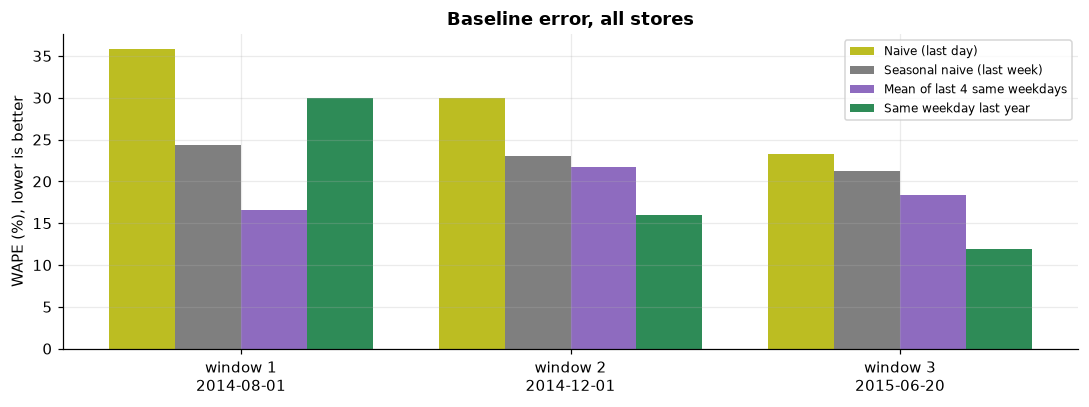

Share of store-days where each rule can produce a forecast (%):
window                            1      2      3
model                                            
Mean of last 4 same weekdays   99.9   96.1  100.0
Naive (last day)              100.0  100.0  100.0
Same weekday last year        100.0   99.4  100.0
Seasonal naive (last week)     99.9   96.1  100.0


window,1,2,3,mean
WAPE (%),,,,
Mean of last 4 same weekdays,16.6,21.7,18.3,18.9
Naive (last day),35.8,30.0,23.3,29.7
Same weekday last year,29.9,16.0,11.9,19.3
Seasonal naive (last week),24.3,23.1,21.3,22.9


In [3]:
from rossmann_forecast.baselines import baseline_forecasts

actual = panel.sales
rows = []
store_ids = pd.Index(panel.stores)
scored = {}
for f in folds:
    base = baseline_forecasts(panel, f)
    y = actual.loc[f.test_start : f.test_end].stack().dropna().rename("y").reset_index()
    y.columns = ["date", "store_id", "y"]
    merged = base.merge(y, on=["date", "store_id"])
    scored[f.index] = merged
    for m in ["naive_last", "snaive", "snaive_mean4", "last_year"]:
        valid = merged.dropna(subset=[m])
        rows.append({"window": f.index, "model": NAMES[m], "WAPE": wape(valid["y"], valid[m]) * 100,
                     "coverage": len(valid) / len(merged) * 100, "m": m})
res = pd.DataFrame(rows)
pivot = res.pivot(index="model", columns="window", values="WAPE").round(1)
pivot["mean"] = pivot.mean(axis=1).round(1)
coverage = res.pivot(index="model", columns="window", values="coverage").round(1)
fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(folds))
for j, m in enumerate(["naive_last", "snaive", "snaive_mean4", "last_year"]):
    sub = res[res["m"] == m]
    ax.bar(x + (j - 1.5) * 0.2, sub["WAPE"], 0.2, label=NAMES[m], color=COLORS[m])
ax.set_xticks(x, [f"window {f.index}\n{f.test_start.date()}" for f in folds])
ax.set_ylabel("WAPE (%), lower is better")
ax.set_title("Baseline error, all stores")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()
print("Share of store-days where each rule can produce a forecast (%):")
print(coverage.to_string())
pivot.rename_axis("WAPE (%)")

A rule is scored only where it can make a forecast (a store with no sales in the weeks before the
origin has nothing to repeat); the coverage table printed above shows how often that happens.

Same weekday last year wins in December (it captures Christmas) but is weak in August and June:
promo weeks alternate and rarely line up from one year to the next. The mean of the last four
same weekdays is steadier but blind to seasonality.

## 3. Prophet, one model per store

In [4]:
from rossmann_forecast.statistical import prophet_forecasts, sample_stores

stores = [1, *[int(s) for s in sample_stores(panel.stores, 5)]]
print("stores:", stores)
prophet, secs = prophet_forecasts(panel, final_fold, stores, n_jobs=4)
y = panel.sales.loc[final_fold.test_start : final_fold.test_end].stack().dropna().rename("y").reset_index()
y.columns = ["date", "store_id", "y"]
cmp = scored[final_fold.index][["date", "store_id", "snaive_mean4", "last_year"]].merge(prophet, on=["date", "store_id"]).merge(y, on=["date", "store_id"])
print(f"seconds per Prophet fit: {secs}")
pd.DataFrame(
    {NAMES[m]: [wape(g["y"], g[m]) * 100 for _, g in cmp.groupby("store_id")] for m in ["snaive_mean4", "last_year", "prophet_plain", "prophet_promo"]},
    index=sorted(cmp["store_id"].unique()),
).round(1).rename_axis("WAPE (%) by store")

stores: [1, 100, 483, 489, 729, 861]


seconds per Prophet fit: {'prophet_plain': 0.3435588999976365, 'prophet_promo': 0.25390546667040326}


,Mean of last 4 same weekdays,Same weekday last year,Prophet per store,Prophet per store + promo
WAPE (%) by store,,,,
1,14.7,8.7,15.1,7.3
100,14.1,12.5,37.8,39.4
483,22.2,11.3,21.1,12.5
489,23.6,10.7,24.0,10.8
729,19.8,8.1,18.3,10.1
861,16.5,11.4,15.5,10.1


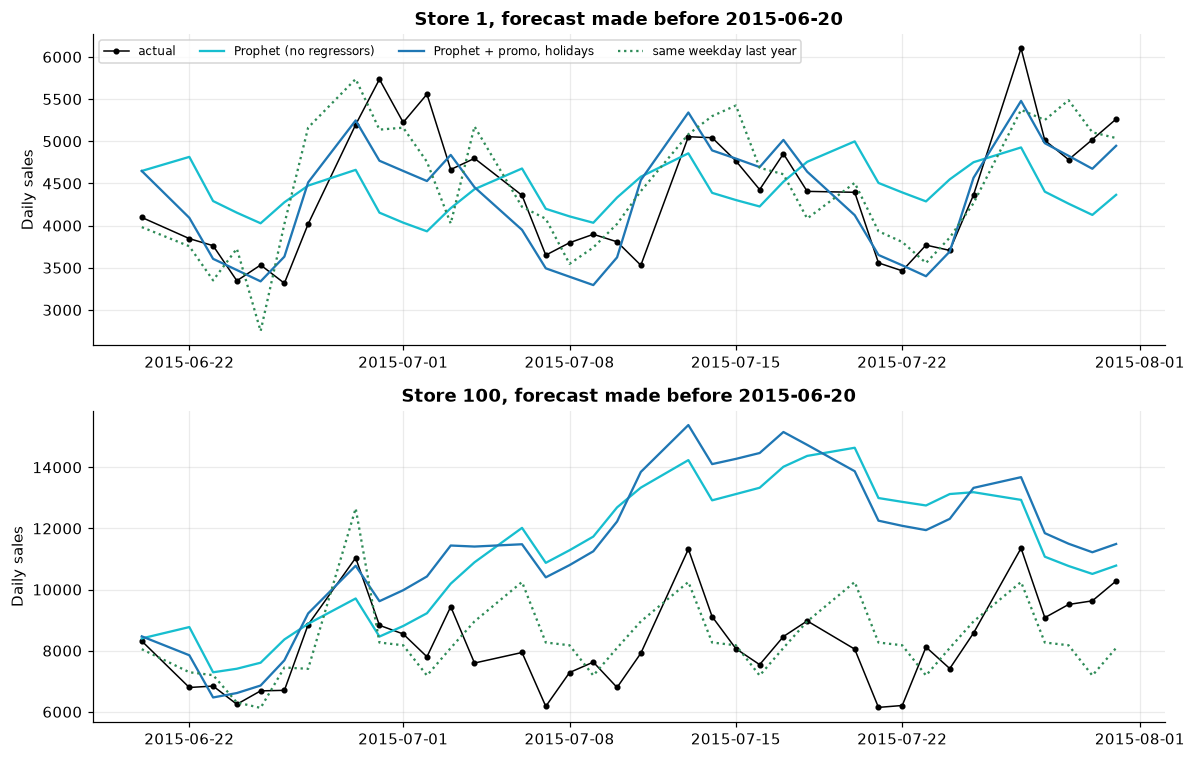

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7))
for ax, s in zip(axes, stores[:2], strict=True):
    g = cmp[cmp["store_id"] == s].sort_values("date")
    ax.plot(g["date"], g["y"], "o-", color="black", ms=3, lw=1, label="actual")
    ax.plot(g["date"], g["prophet_plain"], color=COLORS["prophet_plain"], label="Prophet (no regressors)")
    ax.plot(g["date"], g["prophet_promo"], color=COLORS["prophet_promo"], label="Prophet + promo, holidays")
    ax.plot(g["date"], g["last_year"], color=COLORS["last_year"], ls=":", label="same weekday last year")
    ax.set_title(f"Store {s}, forecast made before {final_fold.test_start.date()}")
    ax.set_ylabel("Daily sales")
axes[0].legend(ncol=4, fontsize=8)
fig.tight_layout()
plt.show()

Plain Prophet sees only the history and cannot know which weeks are promo weeks, so it misses the
weekly promo pattern. Giving it the planned promo and holiday calendar closes much of the gap.

## 4. SARIMAX, one model per store

The old notebooks fitted SARIMAX on a series with closed days deleted, so a "weekly" period of 7
did not line up with real weeks. Here the series keeps every calendar day and treats closed days
as missing, so the weekly period is honestly 7 days. The planned promo flag is an external input.

In [6]:
import time

from statsmodels.tsa.statespace.sarimax import SARIMAX

def sarimax_forecast(store, fold, use_promo):
    j = int(np.where(panel.stores == store)[0][0])
    train_idx = panel.dates < fold.test_start
    y_train = panel.sales.iloc[:, j][train_idx]
    # start in 2014 to keep the fit quick; the weekly and yearly level is carried by the recent past
    y_train = y_train.loc["2014-01-01":]
    exog_tr = panel.promo.iloc[:, j].astype(float).loc[y_train.index] if use_promo else None
    window = pd.date_range(fold.test_start, fold.test_end)
    exog_fu = panel.promo.iloc[:, j].astype(float).loc[window] if use_promo else None
    model = SARIMAX(np.log(y_train), exog=exog_tr, order=(1, 0, 1), seasonal_order=(1, 1, 1, 7),
                    enforce_stationarity=False, enforce_invertibility=False)
    fit = model.fit(disp=False, maxiter=60)
    pred = np.exp(fit.get_forecast(len(window), exog=exog_fu).predicted_mean)
    return pd.DataFrame({"date": window, "store_id": store, "sarimax": pred.values})

t0 = time.time()
sar = pd.concat([sarimax_forecast(s, final_fold, False).assign(variant="sarimax") for s in stores[:3]]
                + [sarimax_forecast(s, final_fold, True).assign(variant="sarimax_promo") for s in stores[:3]])
print(f"{len(sar) // 42} SARIMAX fits in {time.time() - t0:.0f} s")
sar = sar.merge(y, on=["date", "store_id"])
out = sar.groupby(["store_id", "variant"]).apply(lambda g: wape(g["y"], g["sarimax"]) * 100).unstack().round(1)
out.columns = ["SARIMAX (no regressors)", "SARIMAX + promo"]
out.rename_axis("WAPE (%) by store")

6 SARIMAX fits in 3 s


,SARIMAX (no regressors),SARIMAX + promo
WAPE (%) by store,,
1,14.7,6.9
100,12.7,8.0
483,20.4,12.0


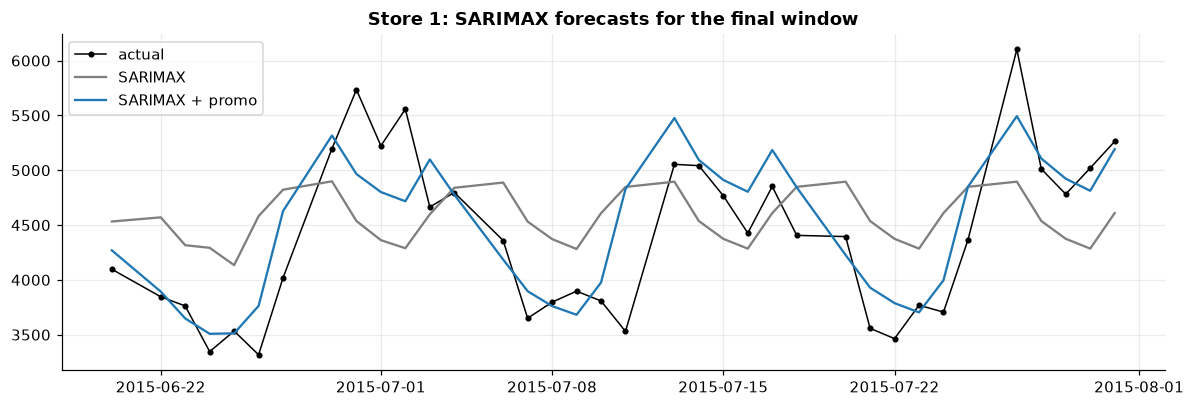

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.8))
s = stores[0]
g = sar[(sar["store_id"] == s)]
ax.plot(g[g["variant"] == "sarimax"]["date"], g[g["variant"] == "sarimax"]["y"], "o-", color="black", ms=3, lw=1, label="actual")
for v, c, lab in [("sarimax", "#7f7f7f", "SARIMAX"), ("sarimax_promo", "#1f77b4", "SARIMAX + promo")]:
    h = g[g["variant"] == v]
    ax.plot(h["date"], h["sarimax"], color=c, label=lab)
ax.set_title(f"Store {s}: SARIMAX forecasts for the final window")
ax.legend()
fig.tight_layout()
plt.show()

## 5. How the per-store models compare at scale

In [8]:
import json

results = json.loads((ROOT / "reports" / "results.json").read_text())
n = results["meta"]["n_prophet_stores"]
sample = results["sample_stores"]
pd.DataFrame(
    {
        "WAPE (mean over 3 windows)": [f"{sample[m]['mean']['wape'] * 100:.1f}%" for m in ["snaive_mean4", "last_year", "prophet_plain", "prophet_promo", "lightgbm"]],
    },
    index=[NAMES[m] for m in ["snaive_mean4", "last_year", "prophet_plain", "prophet_promo", "lightgbm"]],
).rename_axis(f"Same {n} random stores, all three windows")

,WAPE (mean over 3 windows)
"Same 100 random stores, all three windows",
Mean of last 4 same weekdays,19.3%
Same weekday last year,19.5%
Prophet per store,17.9%
Prophet per store + promo,12.5%
Global LightGBM,9.4%


Per-store models need one fit per store (about half a second each for Prophet, more for SARIMAX),
cannot share information between stores, and still lose to one global machine-learning model.
That model is the subject of notebook 03.